# ForecastIQ — Phase 1: Validated classification + 4 forecasting groups

**Goal:** Check M5 data quality, classify product-store series without using the final test period, and select **100 series per demand type** for four separate forecasting workflows.

We reserve the **last 28 days as a final test set**. All demand statistics and categories below use only earlier days. We keep all sales days in the exported sample so Phase 2 can split them chronologically.

**Important:** Historical sales are not always actual demand. Zero sales may be caused by stockouts or product unavailability.

In [1]:
# Shared scientifically validated ForecastIQ framework
import sys
from pathlib import Path
_project = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(_project) not in sys.path:
    sys.path.insert(0, str(_project))
from src.experiments.config import ExperimentConfig, save_manifest
EXPERIMENT_CONFIG = ExperimentConfig()
EXPERIMENT_NAME = '01_data_exploration_full_export'
MANIFEST = save_manifest(_project / 'results' / 'manifests' / (EXPERIMENT_NAME + '.json'), EXPERIMENT_NAME, EXPERIMENT_CONFIG, sources=[_project / 'data' / 'raw' / 'sales_train_validation.csv'])
print('Experiment manifest:', MANIFEST['experiment_id'])


Experiment manifest: 01_data_exploration_full_export-20261101T102815Z


## 1. Import libraries and set the project folder
The path logic works whether you open the notebook from `notebooks/` or run it from the project root.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the project directory
project = Path.cwd()
if not (project / "data").exists() and (project.parent / "data").exists():
    project = project.parent

raw_file = project / "data" / "raw" / "sales_train_validation.csv"
output_dir = project / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

print("Reading:", raw_file)
assert raw_file.exists(), "Download sales_train_validation.csv into data/raw/ first."

## 2. Load and inspect the sales data
Each row represents one **item in one store**; columns `d_1`, `d_2`, etc. represent successive days.

In [3]:
sales = pd.read_csv(raw_file)
day_cols = [c for c in sales.columns if c.startswith("d_")]

print("Products/stores:", len(sales))
print("Daily sales columns:", len(day_cols))
display(sales[["item_id", "store_id"] + day_cols[:5]].head())

Products/stores: 30490
Daily sales columns: 1913


,item_id,store_id,d_1,d_2,d_3,d_4,d_5
0,HOBBIES_1_001,CA_1,0,0,0,0,0
1,HOBBIES_1_002,CA_1,0,0,0,0,0
2,HOBBIES_1_003,CA_1,0,0,0,0,0
3,HOBBIES_1_004,CA_1,0,0,0,0,0
4,HOBBIES_1_005,CA_1,0,0,0,0,0


## 3. Validate data BEFORE calculating statistics
Check for missing, nonnumeric, negative, duplicate, and all-zero series. **Do not silently replace missing values with zero.** Negative sales may be returns or adjustments, so investigate rather than automatically delete.

In [4]:
daily = sales[day_cols]
missing_count = int(daily.isna().sum().sum())
nonnumeric_cols = daily.select_dtypes(exclude="number").columns.tolist()
negative_count = int((daily < 0).sum().sum()) if not nonnumeric_cols else None
duplicate_ids = int(sales.duplicated(subset=["item_id", "store_id"]).sum())
all_zero = int((daily == 0).all(axis=1).sum()) if not nonnumeric_cols else None

print("Missing daily values:", missing_count)
print("Non-numeric daily columns:", nonnumeric_cols[:10])
print("Negative daily values:", negative_count)
print("Duplicate item-store pairs:", duplicate_ids)
print("All-zero series:", all_zero)

# Stop before computing incorrect statistics
assert missing_count == 0, "Investigate missing daily sales before continuing."
assert not nonnumeric_cols, "Investigate nonnumeric sales columns."
assert negative_count == 0, "Investigate negative daily sales before continuing."
assert duplicate_ids == 0, "Investigate duplicate item-store rows."

Missing daily values: 0
Non-numeric daily columns: []
Negative daily values: 0
Duplicate item-store pairs: 0
All-zero series: 0


## 4. Define the training-only observation window

We do **not** calculate ADI, CV², or demand categories using the final 28 days. Otherwise, information about the test period could influence our experiment.

We exclude obvious pre-launch zeros by starting at the first positive sale in the **training period**. We do not know exact product launch dates or stock availability, so this is an approximation.

In [5]:
test_days = 28
assert len(day_cols) > test_days, "Not enough daily columns."
train_cols = day_cols[:-test_days]
test_cols = day_cols[-test_days:]

print("Days used for classification:", len(train_cols))
print("Days reserved for final testing:", len(test_cols))


def calculate_stats(row):
    values = row[train_cols].to_numpy(dtype=float)
    positive_days = np.where(values > 0)[0]

    if len(positive_days) == 0:
        return pd.Series({
            "average_demand": 0.0,
            "zero_sales_ratio": 1.0,
            "ADI": np.nan,
            "CV2": np.nan,
            "positive_days": 0,
            "active_days": 0
        })

    # Analyze from the first positive sale observed during training.
    active = values[positive_days[0]:]
    positive = active[active > 0]

    return pd.Series({
        "average_demand": active.mean(),
        "zero_sales_ratio": (active == 0).mean(),
        "ADI": len(active) / len(positive),
        "CV2": positive.var() / positive.mean()**2 if len(positive) >= 2 else np.nan,
        "positive_days": len(positive),
        "active_days": len(active)
    })


stats = sales.apply(calculate_stats, axis=1)
display(stats.head())

Days used for classification: 1885
Days reserved for final testing: 28


,average_demand,zero_sales_ratio,ADI,CV2,positive_days,active_days
0,0.582317,0.588415,2.429630,0.264357,405.0,984.0
1,0.281860,0.770379,4.355000,0.236099,400.0,1742.0
2,0.348718,0.739744,3.842365,0.300579,203.0,780.0
3,1.750676,0.309356,1.447925,0.588363,1277.0,1849.0
4,1.021433,0.468697,1.882166,0.405940,942.0,1773.0


## 5. Classify the four demand patterns

Using established ADI/CV² cutoffs: **ADI = 1.32**, **CV² = 0.49**.

- Smooth: low ADI, low CV²
- Erratic: low ADI, high CV²
- Intermittent: high ADI, low CV²
- Lumpy: high ADI, high CV²

Series without enough positive observations get an **Insufficient history** label.

In [6]:
from src.data.demand_classification import classify_demand

# Preserve every original identifier/metadata column alongside the derived statistics.
id_columns = [column for column in sales.columns if column not in day_cols]
summary = pd.concat([sales[id_columns].copy(), stats], axis=1)

def demand_type(row):
    return classify_demand(row[train_cols].to_numpy(dtype=float),
                           leading_zero_policy='active')

summary['demand_type'] = sales.apply(demand_type, axis=1)
assert len(summary) == len(sales)
print(summary['demand_type'].value_counts())


demand_type
Intermittent            22179
Lumpy                    5561
Smooth                   1895
Erratic                   854
Insufficient history        1
Name: count, dtype: int64


## 6. Visualize demand categories (training-only classification)

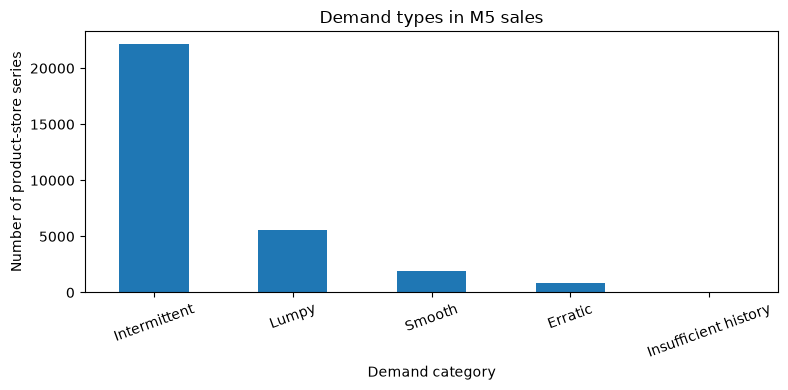

In [7]:
summary["demand_type"].value_counts().plot(kind="bar", figsize=(8, 4))
plt.title("Demand types in M5 sales")
plt.ylabel("Number of product-store series")
plt.xlabel("Demand category")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 7. Compare Smooth and Intermittent examples

The charts show **training history only**. The final 28 test days are not used for examples or category decisions.

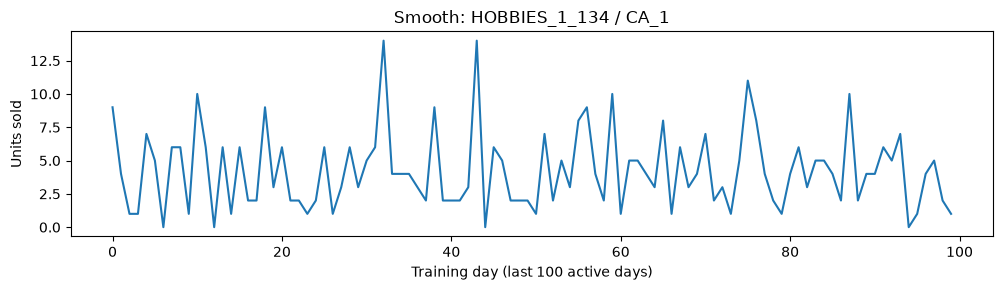

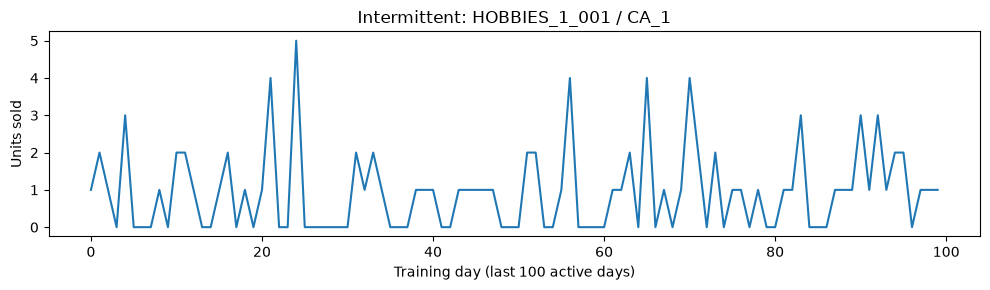

In [8]:
def plot_example(category):
    matches = summary.index[summary["demand_type"] == category]
    if len(matches) == 0:
        print("No example found:", category)
        return

    index = matches[0]
    values = sales.loc[index, train_cols].to_numpy(dtype=float)
    first = np.where(values > 0)[0][0]
    active = values[first:]

    plt.figure(figsize=(10, 3))
    plt.plot(active[-100:])
    plt.title(f"{category}: {sales.loc[index, 'item_id']} / {sales.loc[index, 'store_id']}")
    plt.xlabel("Training day (last 100 active days)")
    plt.ylabel("Units sold")
    plt.tight_layout()
    plt.show()


plot_example("Smooth")
plot_example("Intermittent")

## 8. Select 100 product-store series from each category

This is a **balanced, stratified pilot sample** (400 total series). It allows us to compare forecasting methods across all four demand types, but it does **not** preserve the real-world distribution.

- Select from training-only labels.
- Use a fixed random seed for reproducibility.
- Keep the full sales timeline in the exported CSV for future train/validation/test splitting.
- Export a separate **metadata table** containing the category and statistics.

**Note:** The sampling and broad category assignment use the pre-test period. When comparing models within rolling CV folds, the model must only fit on each fold's training window. If a future agent reclassifies at each fold, it must recalculate the statistics using only that fold's training window.

In [ ]:
categories = ["Smooth", "Erratic", "Intermittent", "Lumpy"]
sample_ids = []

for category in categories:
    available = summary.index[summary["demand_type"] == category]
    print(f"{category}: {len(available)} available")
    if len(available) < 100:
        raise ValueError(f"Not enough {category} series for a sample of 100")

    selected = pd.Series(available).sample(n=100, random_state=42)
    sample_ids.extend(selected.tolist())

# Sample of full daily sales (including untouched final-test columns)
sample = sales.loc[sample_ids, ["item_id", "store_id"] + day_cols].copy()
sample_metadata = summary.loc[sample_ids].copy()

# Give each row an easy-to-use identifier for joining predictions later
sample.insert(0, "series_id", sample["item_id"] + "__" + sample["store_id"])
sample_metadata.insert(0, "series_id", sample_metadata["item_id"] + "__" + sample_metadata["store_id"])

sample.to_csv(output_dir / "m5_sample_400.csv", index=False)
sample_metadata.to_csv(output_dir / "m5_sample_400_metadata.csv", index=False)
summary.to_csv(output_dir / "phase1_statistics.csv", index=False)

print("\nSample distribution:")
print(sample_metadata["demand_type"].value_counts())
print("Saved 400 series and metadata to", output_dir)

## 9. Check the four workflow groups

You can inspect the four separate groups before forecasting. These are **product-store series**, not necessarily 400 distinct product IDs.

Notebook 2 will need to be expanded to loop over all 400 series; the earlier single-product version is still useful for learning.

In [ ]:
for category in categories:
    rows = sample_metadata[sample_metadata["demand_type"] == category]
    print(f"{category}: {len(rows)} product-store series")

print("\nExample selected series:")
display(sample_metadata[["series_id", "demand_type", "average_demand", "zero_sales_ratio", "ADI", "CV2"]].head(10))

report = [
    "# Phase 1 — Retail Demand Exploration",
    "",
    f"- Total product-store series: {len(sales)}",
    f"- Training days for classification: {len(train_cols)}",
    f"- Final test days reserved: {len(test_cols)}",
    f"- Missing values: {missing_count}",
    f"- Negative values: {negative_count}",
    f"- Duplicate item-store pairs: {duplicate_ids}",
    "",
    "## Demand categories (training-only)",
]
for category, count in summary["demand_type"].value_counts().items():
    report.append(f"- {category}: {count}")
report += [
    "", "## Pilot benchmark design", "",
    "Sample 100 series each from Smooth, Erratic, Intermittent and Lumpy.",
    "Benchmark models using rolling time-series validation, preserving a final 28-day test period.",
    "Do not use final-test information for classification, parameter tuning, or model selection.",
    "", "## Caveats", "",
    "Balanced sampling is designed for category comparison, not population-level performance claims.",
    "Pre-launch periods are approximated by the first observed positive sale.",
    "Recorded zeros may reflect stockouts; availability is not fully observed.",
    "The ADI and CV² classification is descriptive, not proof of which model is best.",
    "", "## Reference", "",
    "Syntetos, Boylan & Croston (2005): https://doi.org/10.1057/palgrave.jors.2601841"
]
report_path = output_dir / "phase1_report.md"
report_path.write_text("\n".join(report), encoding="utf-8")
print("Saved:", report_path)

### Phase 1 complete

You now have:
- Training-only statistics and categories
- Validated input data (subject to the limits of observed sales)
- An equal-sized sample of 100 series per demand category
- `data/processed/m5_sample_400.csv` (full sales histories)
- `data/processed/m5_sample_400_metadata.csv` (categories and statistics)
- `data/processed/phase1_statistics.csv` and `phase1_report.md`

**Next:** Update Notebook 2 so it reads these 400 series, runs candidate models in four workflows, performs time-series cross-validation, and evaluates selected models on the final 28 days.

## 10 — Export full M5 dataset for large-scale experiments

This **extends** the original notebook. The existing 400-series CSV files remain unchanged. The full wide sales panel is saved as a memory-efficient Parquet (or CSV fallback) with a separate metadata table. These are the **1,885 observed days in `sales_train_validation.csv`**: the last 28 are retained for evaluation and never used to determine demand classes.

**IMPORTANT:** This file has 30,490 bottom-level product-store series, not the aggregated M5 hierarchy. Recompute classifications per origin before earlier rolling-window backtests, because the fixed metadata cutoff is the final-test origin.

In [11]:
# Full-series metadata retains the SAME training-only classification as the pilot.
full_sales = sales[['item_id','store_id']+day_cols].copy()
full_sales.insert(0,'series_id',full_sales.item_id.astype(str)+'__'+full_sales.store_id.astype(str))
full_metadata = summary.copy()
full_metadata.insert(0,'series_id',full_metadata.item_id.astype(str)+'__'+full_metadata.store_id.astype(str))
assert len(full_sales)==len(full_metadata)==len(sales)
assert full_sales.series_id.is_unique and full_metadata.series_id.is_unique
assert full_sales.series_id.equals(full_metadata.series_id)
assert set(sample.series_id).issubset(set(full_sales.series_id))
for c in day_cols:
    full_sales[c]=pd.to_numeric(full_sales[c],errors='raise').astype('int16')
# Stable CSV-only output contract for downstream notebooks.
full_sales.to_csv(output_dir/'m5_full_sales.csv',index=False)
full_metadata.to_csv(output_dir/'m5_full_metadata.csv',index=False)
print('Saved canonical full-panel CSV exports')
print('Series:',len(full_sales),'| day columns:',len(day_cols),'| classification through:',train_cols[-1])
print('Categories:',full_metadata.demand_type.value_counts().to_dict())

Saved full Parquet exports
Series: 30490 | day columns: 1913 | classification through: d_1885
Categories: {'Intermittent': 22179, 'Lumpy': 5561, 'Smooth': 1895, 'Erratic': 854, 'Insufficient history': 1}


### Export contract
- `m5_sample_400.csv` and `m5_sample_400_metadata.csv` — original pilot, unchanged.
- `m5_full_sales.csv` and `m5_full_metadata.csv` — canonical full-panel files.
- Without `pyarrow`, CSV fallbacks are written instead.

Run Notebook 2B and 3C after this export. The time cutoff for the last 28-day test remains unchanged.